</br>
<div style="display: flex; justify-content: space-between; align-items: flex-start; border-bottom: 2px solid #555555; padding-bottom: 15px; margin-bottom: -8px;">
    <div style="width: 50%;">
        <h2>
            <span style="color: #B30033;">▍</span>Práctica 1:
        </h2>
        <h1 style="margin-top: -10px;">
            Análisis, procesamiento y validación
        </h1>
    </div>
    <div style="width: 50%; text-align: right;">
        <div style="display: flex; justify-content: space-between; align-items: flex-start; margin-top: 30px;">
            <div style="width: 20%;"></div>
            <div style="width: 80%; border-left: 2px solid #555555; padding-left: 20px;">
                <div style="margin-bottom: 20px;">
                    <p style="margin: 0; font-size: 1.4em; font-weight: bold;">
                        Minería de Datos, 2026-27
                    </p>
                </div>
                <div style="margin-top: 8px; text-align: right;">
                    <span style="font-size: 1em; color: #D0D0D0;">
                        José Antonio Gámez Martín
                    </span>
                    <a href="mailto:Jose.Gamez@uclm.es" style="text-decoration: none; color: #888888; font-size: 0.8em; padding-left: 15px;">
                        ✉ Jose.Gamez@uclm.es
                    </a>
                </div>
                <div style="margin-top: 8px; text-align: right;">
                    <span style="font-size: 1em; color: #D0D0D0;">
                        Pablo Torrijos Arenas
                    </span>
                    <a href="mailto:Pablo.Torrijos@uclm.es" style="text-decoration: none; color: #888888; font-size: 0.8em; padding-left: 15px;">
                        ✉ Pablo.Torrijos@uclm.es
                    </a>
                </div>
                </div>
            </div>
        </div>
    </div>
</div>

<div style="border-bottom: 2px solid #555555; padding-bottom: 25px; margin-bottom: 10px">
    <div style="display: flex; align-items: center; margin-bottom: 10px;">
        <span style="color: #B30033; font-size: 1.5em; margin-right: 10px;">▍</span>
        <h3 style="margin: 0; font-size: 1.4em; font-weight: bold">
            Estudiantes
        </h3>
    </div>
    <ul style="list-style-type: none; padding-left: 28px; margin: 0;  font-size: 1.1em">
        <li>Estudiante 1</li>
        <li>(Estudiante 2)</li>
    </ul>

</div>

## 1. Introducción

El objetivo de esta práctica es aplicar las técnicas de un flujo de trabajo de **minería de datos** para resolver un problema de **clasificación supervisada**. Se analizará un conjunto de datos sobre el rendimiento y la actividad de estudiantes universitarios para predecir la probabilidad de abandono de sus estudios.

El desarrollo abarcará desde el **análisis exploratorio** de los datos y su **preprocesamiento**, hasta el **entrenamiento** de un modelo y su **validación** robusta. 

El rendimiento de los modelos se evaluará en una competición privada en Kaggle, que abarcará esta Práctica 1 y la Práctica 2 (selección de modelos).

<div style="border-bottom: 2px solid #555555; padding-bottom: 15px; margin-bottom: 10px">

## 2. Carga y visualización de los datos

Se proporciona un conjunto de datos sintético que simula el rendimiento académico y la interacción de estudiantes durante su primer año. Los datos contienen una variedad de tipos de variables, valores faltantes y otros artefactos que deberán ser gestionados.

Comenzamos importando las librerías necesarias y cargando los conjuntos de datos de entrenamiento (`train`) y de prueba (`test`) para poder examinarlos:

In [8]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)

df_train = pd.read_csv('uclm_student_train.csv')
df_train

,id,nombre,nacimiento,provincia,residencia_id,titulacion,via_acceso,nota_acceso,bachillerato,trabaja,horas_trabajo,modalidad,creditos_a1,superados_a1,nota_s1,satisfaccion,horas_moodle,uso_biblioteca,eventos,tutorias,comentarios,numero_fav,talla_zapato,color_fav,meses_matriculado,grupo_trabajo,abandono
0,CR-2018-BCG465,Berta Calderon Giménez,1995-12-02,Albacete,E1-P00-H12,Bellas Artes,Ciclo Formativo de Grado Superior,"7,09",SOCIAL,0,NaN,Tiempo completo,60,60,"8,57","4,15",~5.5 horas,3,0,2,NaN,46,40,Beige pálido,12,GR007497,0
1,TO-2014-CFB931,Celestina Font Barranco,1996-02-25,Ciudad Real,E1-P02-H17,Doble Grado Derecho-ade,PAU / Bachillerato,"6,79",Humanidades,0,NaN,Tiempo completo,60,24,"4,75",2.51,9.1,8,1,2,Situacion academica estable. Respeta las regla...,69,35,Marrón claro,6,GR003647,0
2,CR-2014-ICS169,Irene Carranza Salvador,1968-08-02,Ciudad Real,E1-P00-H16,Derecho,Mayores de 25 años,"5,00",HUMANIDADES,1,40.0,Tiempo completo,60,42,6.19,"3,11","~3,9 horas",9,0,0,Ausencias injustificadas en seminarios. No int...,16,40,Violeta claro,5,GR003040,1
3,AB-2017-ECG641,Elodia Carmona Gisbert,2000-02-10,Albacete,NaN,Medicina,Ciclo Formativo de Grado Superior,"6,41",Ciencias Puras,0,NaN,Tiempo completo,60,42,"5,14",2.51,~8.2 horas,7,3,3,Uso habitual de la plataforma Moodle. Uso habi...,68,39,Rosa oscuro,6,GR006101,0
4,CR-2013-SGC508,Sara Guillén Cornejo,1996-01-29,Ciudad Real,NaN,Ingeniería Informática,PAU / Bachillerato,"9,05",cientifico,0,NaN,Tiempo completo,60,6,"2,68","1,16",~6.2 horas,1,2,0,Uso habitual de la plataforma Moodle. Interacc...,95,37,Violeta intenso,6,GR002005,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41081,TO-2018-GDM832,Gala de Meléndez,2000-07-15,Toledo,NaN,Comunicación Audiovisual,Ciclo Formativo de Grado Superior,"7,42",Económico,0,NaN,Tiempo completo,60,48,"6,55","3,29",~5.4 horas,4,2,0,Barreras de conciliacion con el desplazamiento...,89,36,Salmón claro,12,GR008301,0
41082,CU-2014-MCB088,Maximino Campoy Benítez,1996-11-20,Cuenca,NaN,Derecho,PAU / Bachillerato,"11,08",ECONÓMICO,0,NaN,Tiempo parcial,36,36,"7,31","3,58",~7.4 horas,0,2,1,Cumple siempre con trabajos. Contacta por corr...,13,47,Índigo pálido,6,GR003339,0
41083,CR-2015-XL601,Xavier Landa-Galván,1969-04-11,Álava,NaN,Ingeniería Mecánica,Mayores de 25 años,"7,78",ciencias puras,1,25.0,Tiempo completo,60,60,"5,65","2,67",~9.2 horas,5,2,2,No asiste a seminarios. Participacion moderada...,58,43,Marrón oscuro,6,GR004337,1
41084,CR-2012-BOI015,Begoña Olivares Iriarte,1995-01-31,Toledo,NaN,Historia del Arte,PAU / Bachillerato,7.74,Humanidades,0,NaN,Tiempo parcial,36,30,"7,15","4,13",~9.1 horas,6,3,2,NaN,23,34,Violeta pálido,6,GR000405,0


In [9]:
df_test = pd.read_csv('uclm_student_test.csv')
df_test

,id,nombre,nacimiento,provincia,residencia_id,titulacion,via_acceso,nota_acceso,bachillerato,trabaja,horas_trabajo,modalidad,creditos_a1,superados_a1,nota_s1,satisfaccion,horas_moodle,uso_biblioteca,eventos,tutorias,comentarios,numero_fav,talla_zapato,color_fav,meses_matriculado,grupo_trabajo
0,CU-2019-RFV844,Remigio Ferrera Vázquez,2001-03-27,Cuenca,NaN,Doble Grado Derecho-ade,PAU / Bachillerato,"8,68",SOCIAL,0,NaN,Tiempo completo,60,48,6.80,"3,46",~6.7 horas,3,2,2,Incomparecencia en las sesiones de seguimiento...,55,39,Ocre claro,12,GR009189
1,AB-2020-RR266,Rosalía Rojas,2002-07-23,Ciudad Real,E1-P03-H14,Comunicación Audiovisual,Ciclo Formativo de Grado Superior,"8,27",SOCIAL,1,40.0,Tiempo completo,60,60,"8,07","3,92",5.5,11,2,1,Uso del entorno virtual sin particularidades. ...,35,38,Granate,8,GR009871
2,CR-2019-FFC269,Felicia Ferreras Colom,2002-01-05,Ciudad Real,NaN,Criminología,Ciclo Formativo de Grado Superior,"5,00",humanidades,0,NaN,Tiempo completo,60,60,8.64,"4,57",~6.5 horas,2,3,2,Gestion ejemplar de el cuidado familiar. Adher...,22,36,Caqui oscuro,12,GR008954
3,AB-2020-OFC312,Ofelia Ferrández Carranza,2002-12-14,Badajoz,NaN,Administración y Dirección de Empresas,PAU / Bachillerato,"9,10",humanidades,1,40.0,Tiempo completo,60,30,"4,45","2,25",7.4,3,2,1,Uso del entorno virtual sin particularidades. ...,6,40,Lima oscuro,10,GR009879
4,CR-2019-MRP759,Máxima Rosselló Palomares,2001-10-27,Ciudad Real,NaN,Ingeniería Mecánica,PAU / Bachillerato,8.61,Ciencias,0,NaN,Tiempo completo,60,24,"2,95","1,41",~8.3 horas,3,0,1,incidencias registradas en el programa de ment...,14,37,Turquesa intenso,8,GR009056
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11229,CU-2019-FP888,Fanny Pedrero,2001-02-23,Cuenca,NaN,Maestro en Educación Primaria,Ciclo Formativo de Grado Superior,"6,48",ECONÓMICO,0,NaN,Tiempo completo,60,60,8.53,4.33,~2.3 horas,0,3,2,No supera los minimos de la materia basica. Ad...,54,38,Magenta intenso,6,GR009181
11230,CU-2019-MBT460,Miriam Baeza Torralba,2001-04-12,Girona,NaN,Doble Grado Ade-estudios Internacionales,PAU / Bachillerato,"8,58",Económico,0,NaN,Tiempo parcial,30,12,"4,30","2,33",~6.7 horas,5,2,0,NaN,15,38,Plata,11,GR009205
11231,CR-2019-EJF437,Enrique Juliá Fabra,1995-01-26,Ciudad Real,E1-P02-H11,Derecho,Titulado universitario,"8,15",economico,0,NaN,Tiempo completo,60,60,"8,30","4,20","4,1h",4,4,3,NaN,24,46,Magenta,11,GR008919
11232,CR-2019-CAP408,Chema Alejo Peláez Mas,2001-07-08,NaN,E2-P02-H09,"Lenguas y Literaturas Modernas, Francés-inglés",Ciclo Formativo de Grado Superior,"7,22",Social,0,NaN,Tiempo completo,60,60,"8,68","4,67",~6.5 horas,6,1,1,Se ofrece como referente para estudiantes de n...,23,44,Negro,12,GR008774


Las variables disponibles son:
`id`, `nombre`, `nacimiento`, `provincia`, `residencia_id`, `titulacion`, `via_acceso`, `nota_acceso`, `bachillerato`, `trabaja`, `horas_trabajo`, `modalidad`, `creditos_a1`, `superados_a1`, `nota_s1`, `satisfaccion`, `horas_moodle`, `uso_biblioteca`, `eventos`, `tutorias`, `comentarios`, `numero_fav`, `talla_zapato`, `color_fav`, `meses_matriculado`, `grupo_trabajo`, `abandono`.

La variable objetivo es `abandono`, que es binaria:
* **1**: El estudiante abandona los estudios.
* **0**: El estudiante continúa.

Se puede observar cómo hay variables categóricas, numéricas, fechas, texto, valores faltantes... Esto requerirá de un análisis exploratorio y un preprocesamiento.

<div style="border-bottom: 2px solid #555555; padding-bottom: 15px; margin-bottom: 10px">

## 3. Flujo de Trabajo y Requisitos

El desarrollo de la práctica deberá seguir las siguientes etapas:


### 3.1. Análisis Exploratorio de Datos (EDA)

Se debe realizar un análisis inicial para comprender la naturaleza de los datos. Este análisis debe incluir:
* Distribución de la variable objetivo (`abandono`).
* Análisis de valores faltantes.
* Distribución de las variables numéricas y categóricas, valores únicos, outliers...
* Identificación de valores atípicos.
* Relaciones entre las variables y la variable objetivo.

Las conclusiones de este análisis deben servir para justificar las decisiones tomadas en la siguiente etapa.


### 3.2. Preprocesamiento de Datos

Esta etapa es fundamental para preparar los datos antes de la modelización. Las tareas incluyen la imputación de valores faltantes, la codificación de variables categóricas, la ingeniería de características (ej. creación de nuevas variables a partir de las existentes), el escalado de datos o incluso eliminar variables que no nos aporten información.

Este proceso debe de ir totalmente ligado al EDA. Las conclusiones que hayamos sacado en el estudio son las que nos deben guiar en este paso. Del mismo modo, al preprocesar los datos y entrenar los modelos podemos sacar nuevas conclusiones que nos permitan entender mejor los datos (como habéis visto en **CRISP-DM**):

<img src="https://upload.wikimedia.org/wikipedia/commons/b/b9/CRISP-DM_Process_Diagram.png" alt="Diagrama de Proceso CRISP-DM" width="550"/>

**Requisito obligatorio**: Todo el proceso de transformación de datos **debe** encapsularse en `Pipelines` de `scikit-learn`. En la práctica, además de mantener una mayor claridad y estructura en el código, esto nos ayudará a evitar fugas de datos.


### 3.3. Modelización y Validación

Se debe entrenar y evaluar correctamente **al menos un algoritmo** (ej. Árboles de Decisión, Naive Bayes, etc.). En esta práctica no es importante usar el mejor modelo posible (eso vendrá en la Práctica 2), sino analizar, preparar y evaluar bien los datos.

**Requisito obligatorio**: La evaluación y comparación de los modelos **debe** realizarse mediante una estrategia de **validación cruzada**. Además, es importante tener en cuenta distintas **métricas** para evaluar nuestro modelo.


### 3.4. Predicción y Evaluación

El modelo final se puede utilizar para generar predicciones sobre el conjunto `uclm_student_test.csv`. Esto es recomendable, pero no es obligatorio en esta práctica (lo será en la Práctica 2).

El fichero de predicciones deberá seguir el formato especificado en `sample_submission.csv`:

In [10]:
df_kaggle = pd.read_csv('sample_submission.csv')
df_kaggle

,id,abandono
0,CU-2019-RFV844,0
1,AB-2020-RR266,1
2,CR-2019-FFC269,0
3,AB-2020-OFC312,0
4,CR-2019-MRP759,1
...,...,...
11229,CU-2019-FP888,0
11230,CU-2019-MBT460,0
11231,CR-2019-EJF437,0
11232,CR-2019-CAP408,0


<div style="border-bottom: 2px solid #555555; margin-bottom: 10px">

## 4. Competición en Kaggle

La evaluación final se realizará mediante una competición privada en Kaggle. El objetivo es maximizar la métrica **F1-Score**, una medida robusta que tiene en cuenta tanto la precisión como la exhaustividad, especialmente útil en casos con clases desbalanceadas.

* **Enlace a la competición**: []()

Los equipos con mejor rendimiento en el *private leaderboard* recibirán una bonificación en la nota final:
* **1er puesto**: +0.75 puntos.
* **2º puesto**: +0.5 puntos.
* **3er puesto**: +0.25 puntos.

**Nota**: Las bonificaciones están sujetas a la revisión del código y la metodología. Se podrá requerir una justificación del enfoque para verificar la originalidad y la comprensión del trabajo.

# 5. Análisis exploratorio de datos 
# 5.1 Distribución de la variable objetivo

abandono vale 0(continua) o 1(abandona) cuantos estudiantes hay de cada clase y en que proporcion ?

In [18]:
#Imports necesarios
import matplotlib.pyplot as plt 
import seaborn as sns


In [19]:
#Conteo y faltantes

df_train['abandono'].value_counts(dropna=False)
#si hubiera faltantes apareceria una fila NaN con su conteo


abandono
0    26969
1    14117
Name: count, dtype: int64

In [20]:
#Porcentajes
(df_train['abandono'].value_counts(normalize=True) * 100).round(3)
#normalize=True, divide cada conteo entre el total de fila, asi obtenemos proporciones


abandono
0    65.64
1    34.36
Name: proportion, dtype: float64

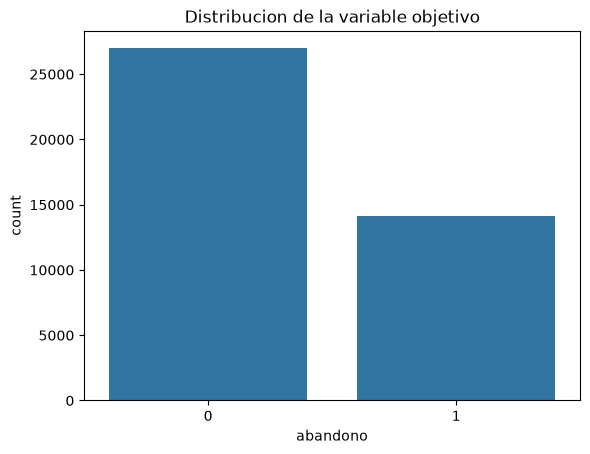

In [21]:

#grafico
sns.countplot(data=df_train, x='abandono')
plt.title('Distribucion de la variable objetivo')
plt.show()

## 5.2 Analisis de Valores faltantes

In [31]:
#verificar valores faltantes en todas las columnas 

df_train.isna().sum()

id                       0
nombre                   0
nacimiento               0
provincia             2512
residencia_id        30128
titulacion               0
via_acceso               0
nota_acceso              0
bachillerato             0
trabaja                  0
horas_trabajo        36028
modalidad                0
creditos_a1              0
superados_a1             0
nota_s1               2424
satisfaccion          2424
horas_moodle             0
uso_biblioteca           0
eventos                  0
tutorias                 0
comentarios           8220
numero_fav               0
talla_zapato             0
color_fav                0
meses_matriculado        0
grupo_trabajo            0
abandono                 0
dtype: int64

In [32]:
#lo pasamos a porcentaje, faltante del total de cada dato

(df_train.isna().mean()*100).sort_values(ascending=False)

horas_trabajo        87.689237
residencia_id        73.329115
comentarios          20.006815
provincia             6.114005
nota_s1               5.899820
satisfaccion          5.899820
id                    0.000000
horas_moodle          0.000000
grupo_trabajo         0.000000
meses_matriculado     0.000000
color_fav             0.000000
talla_zapato          0.000000
numero_fav            0.000000
tutorias              0.000000
eventos               0.000000
uso_biblioteca        0.000000
superados_a1          0.000000
nombre                0.000000
creditos_a1           0.000000
modalidad             0.000000
trabaja               0.000000
bachillerato          0.000000
nota_acceso           0.000000
via_acceso            0.000000
titulacion            0.000000
nacimiento            0.000000
abandono              0.000000
dtype: float64

In [33]:
# por que falta tanto horas de trabajo? 

df_train['trabaja'].value_counts(normalize=True)*100

trabaja
0    82.578007
1    17.421993
Name: proportion, dtype: float64

In [34]:
#comparacion trabaja y horas de trabajo

pd.crosstab(df_train['trabaja'], df_train['horas_trabajo'].isna())

horas_trabajo,False,True
trabaja,,
0,0,33928
1,5058,2100


In [35]:
#mediana o media ?

df_train['horas_trabajo'].describe() #describe ignora los NaN, hay que fijarnos en el minimo, maximos, la media y la mediana 

count    5058.000000
mean       23.532028
std         9.899888
min        10.000000
25%        15.000000
50%        25.000000
75%        30.000000
max        40.000000
Name: horas_trabajo, dtype: float64

In [36]:
#importa el hueco para predecir ??

df_train.groupby(['trabaja', df_train['horas_trabajo'].isna()])['abandono'].mean()

trabaja  horas_trabajo
0        True             0.324894
1        False            0.432187
         True             0.432381
Name: abandono, dtype: float64

#### Conclusión: `horas_trabajo`

  Falta en el 87,7 % de las filas (36.028 de 41.086). Al cruzarla con `trabaja` se ven dos tipos de hueco:

  **No trabajan (33.928):** ninguno tiene horas apuntadas, así que el hueco no es un dato perdido sino la forma en que el dataset indica "no 
  aplica". Se rellena con 0, que es el valor real.
  **Trabajan y no tienen horas (2.100):** aquí el dato sí existe y se ha perdido. Se rellena con la mediana de los estudiantes que trabajan (25
  horas).

  **¿Por qué la mediana y no otro valor?** No puede ser 0, porque el mínimo entre los que trabajan es 10 horas y se confundirían con los que no 
  trabajan. La media (23,5) y la mediana (25) son muy parecidas y no hay valores extremos (el rango va de 10 a 40), pero la mediana es más 
  robusta y es un valor que aparece en los datos.

  **¿Aporta información el hueco?** No. Entre los que trabajan, la tasa de abandono es del 43,2 % tanto si tienen las horas como si no, así que 
  el dato falta al azar y no hace falta una columna que lo marque. Tampoco conviene eliminar esas filas: se perdería un 5 % de los datos y en 
  test no se pueden borrar.

  **Decisión para el preprocesamiento:** imputar 0 cuando `trabaja = 0` y la mediana calculada solo entre los que trabajan cuando `trabaja = 1`.
  robusta y es un valor que aparece en los datos.

  **¿Aporta información el hueco?** No. Entre los que trabajan, la tasa de abandono es del 43,2 % tanto si tienen las horas como si no, así que
  el dato falta al azar y no hace falta una columna que lo marque. Tampoco conviene eliminar esas filas: se perdería un 5 % de los datos y en
  test no se pueden borrar.

  **Decisión para el preprocesamiento:** imputar 0 cuando `trabaja = 0` y la mediana calculada solo entre los que trabajan cuando `trabaja = 1`.

  Además, se observa que los estudiantes que trabajan abandonan más (43,2 %) que los que no (32,5 %), por lo que `trabaja` parece una variable
  útil para el modelo.

## Ahora aplicamos el mismo proceso para 'residencia_id'


In [37]:
df_train['residencia_id'].value_counts()

residencia_id
E3-P00-H17    62
E3-P02-H10    55
E1-P00-H14    54
E2-P04-H01    53
E2-P00-H20    50
              ..
E1-P01-H04    23
E3-P02-H07    23
E2-P04-H19    22
E3-P04-H03    21
E3-P02-H12    20
Name: count, Length: 300, dtype: int64

In [38]:
df_train['residencia_id'].nunique()
#pensamos en dos cosas, el formato de los codigos de residencia
#cuantos estudiantes comparten cada codigo?
#alta cardinalidad, es categorica con muchas categorias

300

In [39]:
#importa tener residencia o no ?

df_train.groupby(df_train['residencia_id'].isna())['abandono'].mean()

#donde True es la tasa de abandono de los que no tienen residencia y False de los que si
#cambia muy poco, vivir o no en residencia, no cambia la probabilidad de abandonar

residencia_id
False    0.345045
True     0.343070
Name: abandono, dtype: float64

# Que se concluye hasta ahora ?

-> Un 73% sin codigo significa que eso estudiantes no viven en residencia, lo mejor seria tratarlos como categoria propia, 'sin residencia'

-> Tener o no residencia no predice nada, segun la tabla anterior

# A pesar de esto queda una pregunta por comprobar, importa en cual de las 300 residencia vivan ?

In [40]:
df_train.groupby('residencia_id')['abandono'].agg(['mean', 'count']).sort_values('mean')
#donde .agg(['mean', 'count']) calcula dos cosas por residencia: la tasa de abandono y cuantos estudiantes tiene

,mean,count
residencia_id,,
E1-P03-H08,0.050000,40
E2-P02-H12,0.100000,30
E3-P02-H11,0.133333,30
E2-P03-H14,0.135135,37
E2-P02-H20,0.161290,31
...,...,...
E3-P04-H20,0.558824,34
E1-P00-H06,0.562500,32
E3-P03-H06,0.594595,37


#### Conclusión: 'residencia_id'

Falta en el 73,3 % de las filas (30.128 de 41.086). El hueco no es un dato perdido: indica que el estudiante no vive en residencia.

* **Tipo de variable:** aunque se llama "id", no identifica a una persona. Hay 300 códigos distintos con formato edificio-planta-habitación 
(por ejemplo `E3-P00-H17`), cada uno compartido por entre 20 y 62 estudiantes. Es una variable categórica de alta cardinalidad.
* **¿Importa tener o no residencia?** No. La tasa de abandono es del 34,5 % entre los que viven en residencia y del 34,3 % entre los que no.
* **¿Importa la residencia concreta?** La tasa de abandono por código va del 5 % al 65 %, pero cada grupo tiene muy pocos estudiantes, así que 
gran parte de esa variación se debe al azar y no a un efecto real de la residencia.

* **Decisión para el preprocesamiento:** eliminar la columna. Tener o no residencia no aporta información, y mantener los 300 códigos añadiría 
muchas columnas con pocos datos en cada una y riesgo de que el modelo memorice ruido.

## Pasamos con las variables 'nota_s1' y 'satisfaccion'

Vemos que en la parte de faltantes ambas tienen el mismo porcentaje de faltantes (5.899820%)

In [41]:
(df_train['nota_s1'].isna() & df_train['satisfaccion'].isna()).sum()
#aqui se devuelve el numero de filas donde faltan nota_s1 y satisfaccion a la vez

np.int64(2424)

In [42]:
df_train.groupby(df_train['nota_s1'].isna())['abandono'].mean()
#aqui se vera que los estudiantes sin nota abandonan casi el doble que los que la tienen

nota_s1
False    0.326134
True     0.622112
Name: abandono, dtype: float64

#### Conclusión: `nota_s1` y `satisfaccion`

Cada una falta en el 5,9 % de las filas (2.424 de 41.086), y faltan exactamente en las mismas: no hay ningún estudiante que tenga una y no la 
otra. No es casualidad; algo hizo que a esos estudiantes no se les registrara ninguno de los dos datos.

* **¿Aporta información el hueco?** Sí, y mucha. Los estudiantes sin nota del primer semestre abandonan en un 62,2 %, frente al 32,6 % de los 
que sí la tienen: casi el doble.
* **Posible explicación:** probablemente son estudiantes que no se presentaron a los exámenes o dejaron de asistir durante el primer semestre, 
    por lo que no tienen nota ni respondieron a la encuesta de satisfacción. Aun así, un 38 % de ellos continúa, así que el hueco es una señal 
  fuerte pero no equivale a abandonar.
* **¿Por qué no rellenar con 0?** Un 0 es una nota posible (presentarse y suspender), así que se mezclarían estudiantes sin nota con 
  estudiantes con la peor nota, y se distorsionaría la distribución de la variable.
* **¿Por qué no solo la mediana?** Esos estudiantes pasarían a parecer alumnos normales y se perdería la información más útil encontrada hasta 
  ahora.

  **Decisión para el preprocesamiento:** crear una columna nueva que marque con 1 a los estudiantes sin nota del primer semestre, e imputar la 
  mediana en `nota_s1` y `satisfaccion`. Basta con una sola columna de marca, porque las dos variables faltan siempre juntas.

## Ahora las variables 'comentarios' y 'provincia'

In [45]:
df_train.groupby(df_train['comentarios'].isna())['abandono'].mean()

comentarios
False    0.345037
True     0.337835
Name: abandono, dtype: float64

In [46]:
df_train.groupby(df_train['provincia'].isna())['abandono'].mean()

provincia
False    0.343807
True     0.340366
Name: abandono, dtype: float64

In [47]:
df_train['provincia'].value_counts()

provincia
Ciudad Real               9800
Toledo                    9313
Albacete                  8920
Cuenca                    6288
Jaén                       114
Palencia                   106
Cádiz                      102
Santa Cruz de Tenerife     101
Valencia                   100
Zaragoza                   100
Cantabria                   99
León                        99
Girona                      98
Baleares                    98
Soria                       96
Huelva                      95
Cáceres                     95
Teruel                      95
Las Palmas                  93
Burgos                      93
Huesca                      93
Salamanca                   92
Lleida                      91
Ávila                       91
Segovia                     91
Ourense                     91
Ceuta                       90
Almería                     90
Navarra                     90
Málaga                      89
Vizcaya                     88
Guipúzcoa                   8

In [50]:
df_train['comentarios'].head(15)
# aqui hacemos dos preguntas: importa que el comentario falte ? No
#importa lo que dice el comentario? Si y bastante

0                                                   NaN
1     Situacion academica estable. Respeta las regla...
2     Ausencias injustificadas en seminarios. No int...
3     Uso habitual de la plataforma Moodle. Uso habi...
4     Uso habitual de la plataforma Moodle. Interacc...
5     No asiste a clase. Situacion academica estable...
6     dificultades para compaginar asistencia y tare...
7     Muestra gran interes por fisica. Expresa dudas...
8     Situacion academica estable. Situacion academi...
9                                                   NaN
10    Uso habitual de la plataforma Moodle. uso habi...
11    Participacion moderada en clase. Participacion...
12    Cumple siempre con trabajos. Perfil de alumno ...
13    Uso del entorno virtual sin particularidades. ...
14    expresa dudas sobre la titulacion. Se detectan...
Name: comentarios, dtype: str

#### Conclusión: `provincia` y `comentarios`

  * **`provincia` (6,1 %, 2.512 filas):** el hueco no está relacionado con el abandono (34,0 % sin provincia frente a 34,4 % con ella), así que
  no hace falta marcarlo. No se imputa la moda porque no hay una provincia claramente dominante (Ciudad Real, Toledo y Albacete tienen tamaños

  * **`provincia` (6,1 %, 2.512 filas):** el hueco no está relacionado con el abandono (34,0 % sin provincia frente a 34,4 % con ella), así que
  no hace falta marcarlo. No se imputa la moda porque no hay una provincia claramente dominante (Ciudad Real, Toledo y Albacete tienen tamaños
  muy parecidos) y asignar todos los huecos a una de ellas la inflaría artificialmente. Se rellena con una categoría nueva, "Desconocida".
  * **`comentarios` (20 %, 8.220 filas):** son observaciones escritas sobre el estudiante, no por él. El hueco indica que no se anotó ninguna
  observación, y tampoco está relacionado con el abandono (33,8 % sin comentarios frente a 34,5 % con ellos). Se trata como texto vacío.

### 5.3 Distribucion de las variables numericas y categoricas y valores unicos 

In [52]:
#tipos de variables que da pandas a cada col

df_train.dtypes


id                       str
nombre                   str
nacimiento               str
provincia                str
residencia_id            str
titulacion               str
via_acceso               str
nota_acceso              str
bachillerato             str
trabaja                int64
horas_trabajo        float64
modalidad                str
creditos_a1            int64
superados_a1           int64
nota_s1                  str
satisfaccion             str
horas_moodle             str
uso_biblioteca         int64
eventos                int64
tutorias               int64
comentarios              str
numero_fav             int64
talla_zapato           int64
color_fav                str
meses_matriculado      int64
grupo_trabajo            str
abandono               int64
dtype: object

In [53]:
#Aqui buscamos el numero de valores distintos en cada columna
df_train.nunique()

id                   36715
nombre               36705
nacimiento            5843
provincia               53
residencia_id          300
titulacion              64
via_acceso               4
nota_acceso           1375
bachillerato            25
trabaja                  2
horas_trabajo            6
modalidad                2
creditos_a1              4
superados_a1            11
nota_s1               1265
satisfaccion           719
horas_moodle          1322
uso_biblioteca          17
eventos                 12
tutorias                11
comentarios          28290
numero_fav             100
talla_zapato            15
color_fav              140
meses_matriculado       12
grupo_trabajo         8382
abandono                 2
dtype: int64

In [68]:
#vemos que id tiene 36.715 valores, pero hay 41.086, veremos que pasa

df_train.duplicated().sum()

np.int64(4371)

In [60]:
# numericas, categoricas y sospechosas

df_train['nota_s1'].sample(20)

13587    7,83
4255     6,12
16123    7,38
26223    7,77
893      8,11
17146    7,44
5990     7,67
6534     7,51
7918     5,90
8581     5,86
26231    6,75
2526     7,97
22543    7,14
21659    4,18
10078    7,70
34906    7,48
22445     NaN
31375    7,98
39429    7,41
26962    5,05
Name: nota_s1, dtype: str

  #### Conclusión: tipos de variables y valores únicos

  **Clasificación de las 27 columnas:**

  * **Numéricas:** `horas_trabajo`, `creditos_a1`, `superados_a1`, `uso_biblioteca`, `eventos`, `tutorias`, `numero_fav`, `talla_zapato`,
  `meses_matriculado`.
  * **Binarias (0/1):** `trabaja` y `abandono` (la variable objetivo).
  * **Categóricas:** `provincia` (53 valores), `titulacion` (64), `via_acceso` (4), `bachillerato` (25), `modalidad` (2), `color_fav` (140).
  * **Categóricas de muy alta cardinalidad:** `residencia_id` (300) y `grupo_trabajo` (8.382).
  * **Identificadores:** `id` y `nombre`. Tienen casi un valor distinto por fila, así que no sirven para predecir.
  * **Fecha:** `nacimiento`.
  * **Texto libre:** `comentarios`.
  * **Numéricas guardadas como texto:** `nota_acceso`, `nota_s1`, `satisfaccion` y `horas_moodle`.

  **Numéricas guardadas como texto.** Pandas las lee como texto porque mezclan varios formatos:

  * `nota_acceso`, `nota_s1` y `satisfaccion`: la mayoría de valores usa coma decimal (`7,83`) y el resto punto (`7.67`).
  * `horas_moodle`: además de mezclar coma y punto, incluye texto junto al número (`~5.5 horas`, `3,9h`, `8.2 h`).

  Habrá que unificar el formato y convertirlas a número antes de poder analizarlas o usarlas en un modelo.

  **Filas duplicadas.** Hay 4.371 filas que son copia exacta de otra, lo que explica que `id` tenga 36.715 valores distintos en 41.086 filas. Se
  eliminarán antes de entrenar: si la misma fila cae a la vez en la parte de entrenamiento y en la de validación, el modelo se evalúa con datos
  que ya ha visto y el resultado sale mejor de lo que es en realidad.

  celda propia para que el texto quede respaldado por una salida.

In [71]:
#verificamos las sospechosas 

df_train['nota_s1'].sample(20)

11445    7.75
3828     7,36
11170    7,63
10612    8,04
4077     7,50
22170    8,19
2580     8,25
3416     5,76
32658    7,37
35190    5,68
1935     5,73
29105    7,72
30064    8,36
6237     6,22
3933     7,12
20071     NaN
33575    7,48
6727     4,15
14136    7,72
8807     4,16
Name: nota_s1, dtype: str

In [72]:
#verificamos las sospechosas 
df_train['satisfaccion'].sample(20)


15556    4,16
27120    4,02
30638    3.51
31539    3,54
22118    4,11
2490     3,23
33866    2,71
15363    3,47
10485     NaN
10560    3,92
29772     NaN
4321     2,89
35965    1,76
30499     NaN
27405    2,69
22813    2,98
16008    2,99
6712     3,81
22545    2,33
32456    2,53
Name: satisfaccion, dtype: str

In [73]:
#verificamos las sospechosas 
df_train['horas_moodle'].sample(20)


40366    ~10.0 horas
2809      ~3.6 horas
27526     ~1.6 horas
23832     ~8.7 horas
40205     ~6.5 horas
16845     ~6.1 horas
41080     ~3.1 horas
26953     ~4.3 horas
12362     ~8.9 horas
40767           8,0h
20999     ~6.5 horas
8072      ~2.5 horas
341       ~2.8 horas
26840     ~2.5 horas
27765     ~8.1 horas
17085     ~6.5 horas
16436     ~5.3 horas
27706     ~8.9 horas
34117     ~9.0 horas
31253          11,5h
Name: horas_moodle, dtype: str

In [74]:
#verificamos las sospechosas 
df_train['nota_acceso'].sample(20)

34284     7,10
15454     9,69
22468     8,64
32527     6,81
38688     9,79
19616    10,32
29045     7,60
27705     8,45
2590      6,77
1720      8.61
3287      7,95
6174      5,08
15569     5,81
39733     6,38
10641     7,61
2349      6,10
39153     8,48
32306     8,30
38890    10,24
14209     7,08
Name: nota_acceso, dtype: str